In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

fileName = "LA_AQS_2023.csv"

df_aqs = pd.read_csv(fileName)
df_aqs["Date (Local)"] = pd.to_datetime(df_aqs["Date (Local)"])

In [60]:
df_O3 = df_aqs[(df_aqs['Parameter Name']=='Ozone') & (df_aqs['Duration Description']=='1 HOUR')].copy()
df_O3["O3"] = df_O3["Arithmetic Mean"]*1000


df_NO2 = df_aqs[(df_aqs['Parameter Name']=='Nitrogen dioxide (NO2)') & (df_aqs['Duration Description']=='1 HOUR')].copy()
df_NO2 = df_NO2.groupby("Date (Local)", as_index=False)["Arithmetic Mean"].mean()
df_NO2["NO2"] = df_NO2["Arithmetic Mean"]

df_PM25 = df_aqs[(df_aqs['Parameter Name']=='PM2.5 - Local Conditions') & (df_aqs['Duration Description']=='1 HOUR')].copy()
df_PM25 = df_PM25.groupby("Date (Local)", as_index=False)["Arithmetic Mean"].mean()
df_PM25["PM25"] = df_PM25["Arithmetic Mean"]

In [61]:
df_all = df_O3[["Date (Local)", "O3"]].merge(df_NO2[["Date (Local)", "NO2"]], on="Date (Local)")

df_all = df_all.merge(df_PM25[["Date (Local)", "PM25"]], on="Date (Local)").dropna()

In [62]:
df_all["Month"] = df_all["Date (Local)"].dt.month
df_all = df_all[df_all["Month"].isin([12, 1, 2, 6, 7, 8])].copy()
df_all["Season"] = np.where(df_all["Month"].isin([6, 7, 8]), "Summer", "Winter")

In [63]:
X_aqs = df_all[["O3", "NO2", "PM25"]].values
y_aqs = np.where(df_all["Season"]=="Summer", 1, -1)

X_train_aqs, X_val_aqs, y_train_aqs, y_val_aqs = train_test_split(X_aqs, y_aqs, test_size=0.2, random_state=20)

scaler_aqs = StandardScaler()
X_train_aqs = scaler_aqs.fit_transform(X_train_aqs)
X_val_aqs = scaler_aqs.transform(X_val_aqs)

In [64]:
alphas = np.arange(0, 1000, 0.1)
best_train_alpha = None
best_val_alpha = None
min_train_error = 100.0
min_val_error = 100.0

for alpha in alphas:
    ridge_aqs = linear_model.RidgeClassifier(alpha=alpha)
    ridge_aqs.fit(X_train_aqs, y_train_aqs)

    train_error = 1 - ridge_aqs.score(X_train_aqs, y_train_aqs)
    val_error = 1 - ridge_aqs.score(X_val_aqs, y_val_aqs)

    if train_error < min_train_error:
        min_train_error = train_error
        best_train_alpha = alpha

    if val_error < min_val_error:
        min_val_error = val_error
        best_val_alpha = alpha

print("Best training alpha:", best_train_alpha)
print("Minimum training error:", min_train_error)
print("Best validation alpha:", best_val_alpha)
print("Minimum validation error:", min_val_error)

Best training alpha: 0.0
Minimum training error: 0.1333333333333333
Best validation alpha: 335.3
Minimum validation error: 0.09677419354838712


In [65]:
ridge_aqs = linear_model.RidgeClassifier(alpha=best_val_alpha)
ridge_aqs.fit(X_train_aqs, y_train_aqs)

print("Validation error:", 1 - ridge_aqs.score(X_val_aqs, y_val_aqs))

Validation error: 0.09677419354838712


In [66]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

df_buoy = pd.read_csv("Waves_2023.txt", sep=r"\s+")
df_buoy = df_buoy[["DPD", "APD", "MWD", "WTMP", "WVHT"]]

df_buoy = df_buoy.replace({"WVHT": 99, "DPD": 99, "APD": 99, "MWD": 999, "WTMP": 999}, np.nan).dropna()

X_buoy = df_buoy[["DPD", "APD", "MWD", "WTMP"]]
y_buoy = df_buoy["WVHT"]

In [67]:
X_train_buoy, X_temp_buoy, y_train_buoy, y_temp_buoy = train_test_split(X_buoy, y_buoy, test_size=0.4, random_state=42)

X_val_buoy, X_test_buoy, y_val_buoy, y_test_buoy = train_test_split(X_temp_buoy, y_temp_buoy, test_size=0.5, random_state=42)

In [68]:
linear_buoy = LinearRegression()
linear_buoy.fit(X_train_buoy, y_train_buoy)

linear_train_mse = mean_squared_error(y_train_buoy, linear_buoy.predict(X_train_buoy))
linear_val_mse = mean_squared_error(y_val_buoy, linear_buoy.predict(X_val_buoy))
linear_test_mse = mean_squared_error(y_test_buoy, linear_buoy.predict(X_test_buoy))

print("Train MSE:", linear_train_mse)
print("Val MSE:", linear_val_mse)
print("Test MSE:", linear_test_mse)

Train MSE: 0.19736134368891822
Val MSE: 0.20048706388324908
Test MSE: 0.1860482618521536


In [69]:
decisiontree_buoy = DecisionTreeRegressor(random_state=42)
decisiontree_buoy.fit(X_train_buoy, y_train_buoy)

decisiontree_train_mse = mean_squared_error(y_train_buoy, decisiontree_buoy.predict(X_train_buoy))
decisiontree_val_mse = mean_squared_error(y_val_buoy, decisiontree_buoy.predict(X_val_buoy))
decisiontree_test_mse = mean_squared_error(y_test_buoy, decisiontree_buoy.predict(X_test_buoy))

print("Train MSE:", decisiontree_train_mse)
print("Val MSE:", decisiontree_val_mse)
print("Test MSE:", decisiontree_test_mse)

Train MSE: 2.9474191992281712e-05
Val MSE: 0.15221752532561506
Test MSE: 0.15090688657407408


In [70]:
from xgboost import XGBRegressor

xgb_buoy = XGBRegressor(n_estimators=1000, objective="reg:squarederror", eval_metric="rmse", early_stopping_rounds=10, random_state=42)

xgb_buoy.fit(X_train_buoy, y_train_buoy, eval_set=[(X_val_buoy, y_val_buoy)], verbose=False)

print(xgb_buoy.best_iteration + 1)

41


In [71]:
from sklearn.inspection import permutation_importance

result_ridge = permutation_importance(ridge_aqs, X_val_aqs, y_val_aqs,scoring="accuracy", n_repeats=20, random_state=42)

result_linear = permutation_importance(linear_buoy, X_val_buoy, y_val_buoy,scoring="neg_mean_squared_error", n_repeats=20, random_state=42)

result_decisiontree = permutation_importance(decisiontree_buoy, X_val_buoy, y_val_buoy,scoring="neg_mean_squared_error", n_repeats=20, random_state=42)

result_xgb = permutation_importance(xgb_buoy, X_val_buoy, y_val_buoy,scoring="neg_mean_squared_error", n_repeats=20, random_state=42)

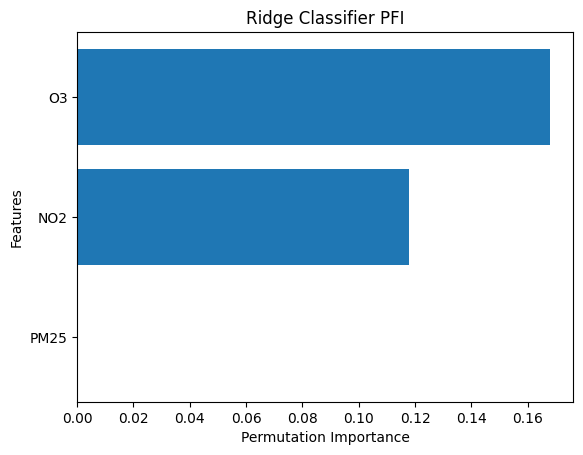

In [72]:
def plot_importance_bar(features, result, title):
    order = np.argsort(result.importances_mean)
    plt.barh(np.array(features)[order], result.importances_mean[order])
    plt.xlabel("Permutation Importance")
    plt.ylabel("Features")
    plt.title(title)
    plt.show()


plot_importance_bar(["O3", "NO2", "PM25"], result_ridge, "Ridge Classifier PFI")

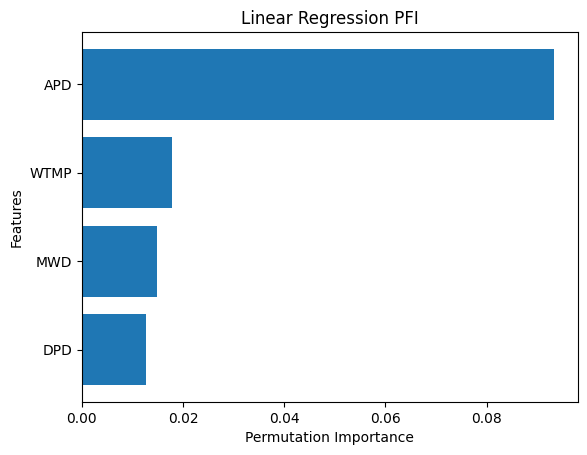

In [73]:
plot_importance_bar(X_train_buoy.columns, result_linear, "Linear Regression PFI")

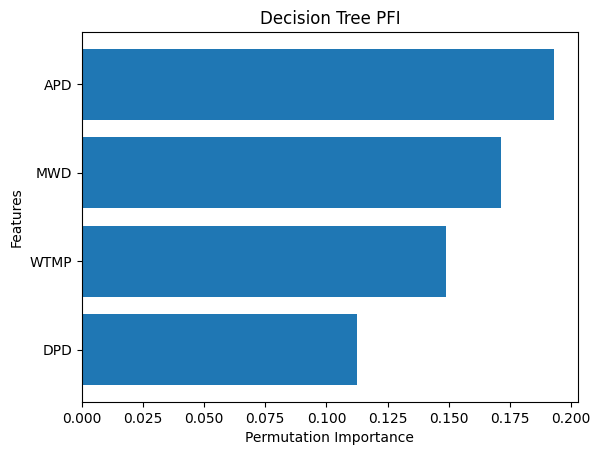

In [74]:
plot_importance_bar(X_train_buoy.columns, result_decisiontree, "Decision Tree PFI")

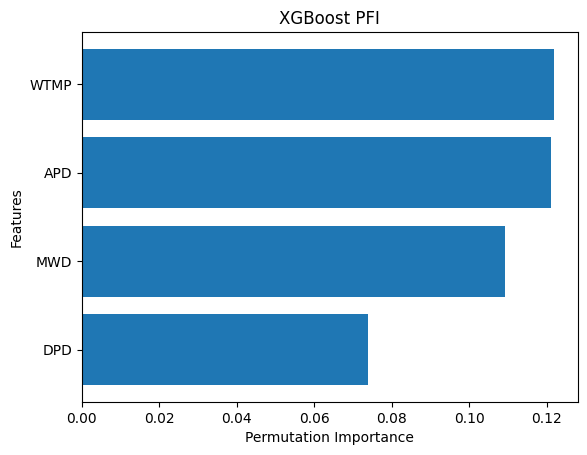

In [75]:
plot_importance_bar(X_train_buoy.columns, result_xgb, "XGBoost PFI")